In [2]:
%pip install seaborn scikit-learn pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams['figure.figsize'] = (10, 6)

In [5]:

column_names = [
    "symboling", "normalized-losses", "make", "fuel-type", "aspiration",
    "num-of-doors", "body-style", "drive-wheels", "engine-location",
    "wheel-base", "length", "width", "height", "curb-weight",
    "engine-type", "num-of-cylinders", "engine-size", "fuel-system",
    "bore", "stroke", "compression-ratio", "horsepower", "peak-rpm",
    "city-mpg", "highway-mpg", "price"
]

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/autos/imports-85.data"
df = pd.read_csv(url, names=column_names, na_values="?")

target = "city-mpg"

continuous_features = [
    "wheel-base", "length", "width", "curb-weight", 
    "engine-size", "bore", "stroke", "compression-ratio", 
    "horsepower", "peak-rpm"
]

data = df[continuous_features + [target]].dropna().copy()

print(f"Dataset shape after cleaning missing values: {data.shape}")
data.head()

Dataset shape after cleaning missing values: (199, 11)


,wheel-base,length,width,curb-weight,engine-size,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg
0,88.6,168.8,64.1,2548,130,3.47,2.68,9.0,111.0,5000.0,21
1,88.6,168.8,64.1,2548,130,3.47,2.68,9.0,111.0,5000.0,21
2,94.5,171.2,65.5,2823,152,2.68,3.47,9.0,154.0,5000.0,19
3,99.8,176.6,66.2,2337,109,3.19,3.40,10.0,102.0,5500.0,24
4,99.4,176.6,66.4,2824,136,3.19,3.40,8.0,115.0,5500.0,18


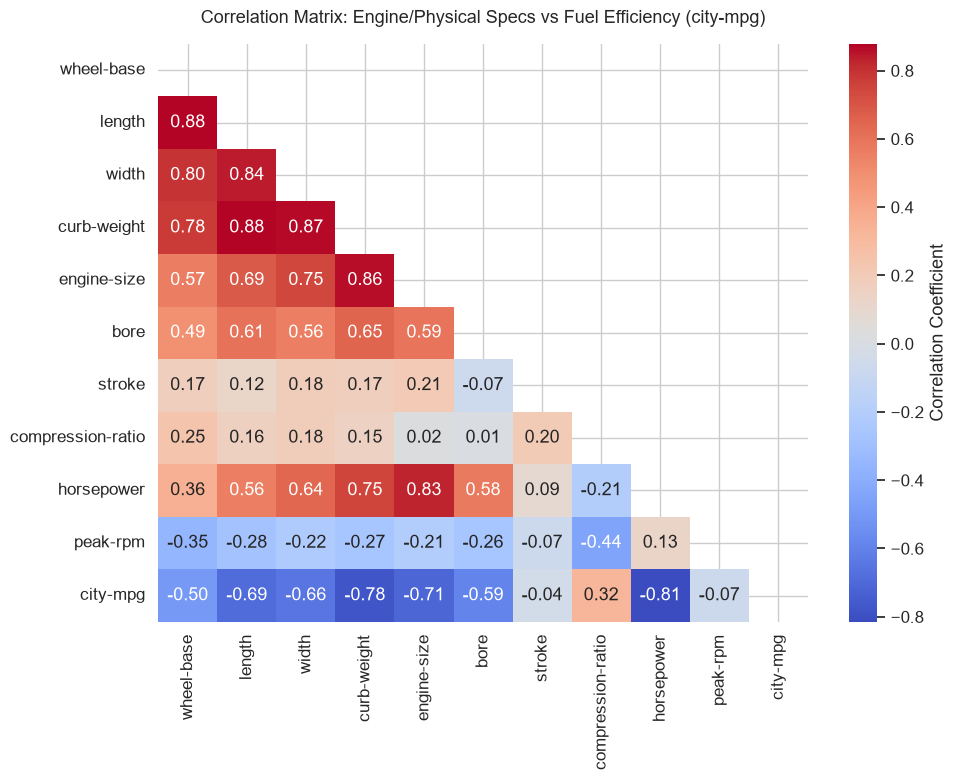

In [6]:
plt.figure(figsize=(10, 8))
corr_matrix = data.corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

sns.heatmap(
    corr_matrix, 
    annot=True, 
    fmt=".2f", 
    cmap="coolwarm", 
    mask=mask,
    cbar_kws={'label': 'Correlation Coefficient'}
)
plt.title("Correlation Matrix: Engine/Physical Specs vs Fuel Efficiency (city-mpg)", pad=15)
plt.tight_layout()
plt.show()

In [ ]:
X = data[continuous_features]
y = data[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = LinearRegression()
model.fit(X_train_scaled, y_train)

y_train_pred = model.predict(X_train_scaled)
y_test_pred = model.predict(X_test_scaled)